<a href="https://colab.research.google.com/github/neha-sharma4/ML-2_Lab/blob/main/ML_lab_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the Iris dataset from sklearn
iris = load_iris()

# Convert to a pandas DataFrame (unsupervised, so we exclude the target labels)
df = pd.DataFrame(iris.data, columns=iris.feature_names)

# Keep the first two features for easy 2D visualization
df = df[[iris.feature_names[0], iris.feature_names[1]]]

display(df.head())


,sepal length (cm),sepal width (cm)
0,5.1,3.5
1,4.9,3.0
2,4.7,3.2
3,4.6,3.1
4,5.0,3.6


/tmp/ipykernel_6707/1409969371.py:6: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=50, cmap='viridis')


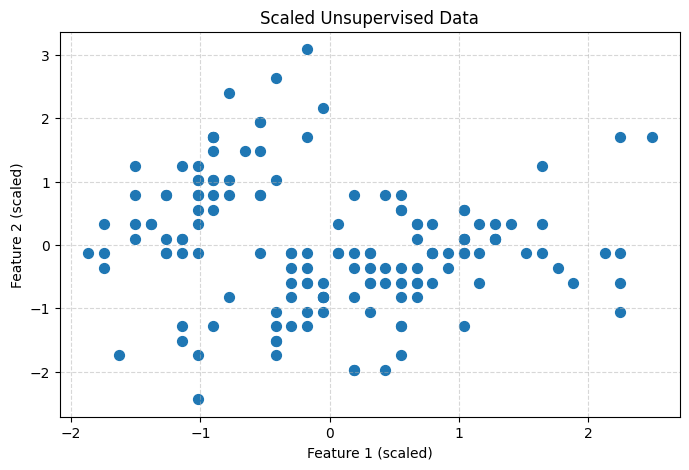

In [2]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df)

# Visualize the unclustered data
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], s=50, cmap='viridis')
plt.title('Scaled Unsupervised Data')
plt.xlabel('Feature 1 (scaled)')
plt.ylabel('Feature 2 (scaled)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

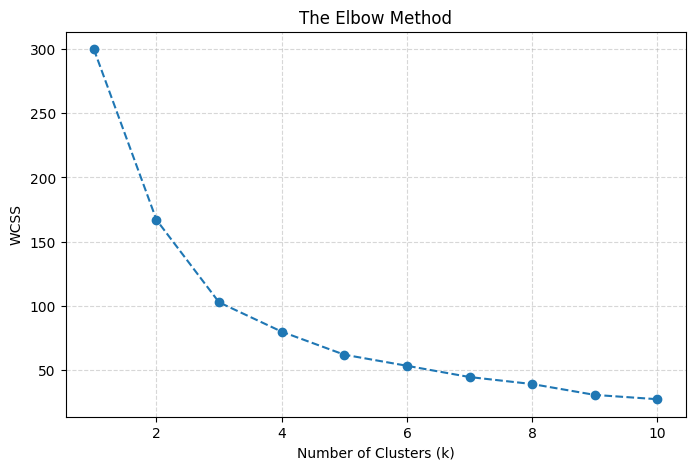

In [5]:
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

# Plot the elbow curve
plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('The Elbow Method')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('WCSS')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

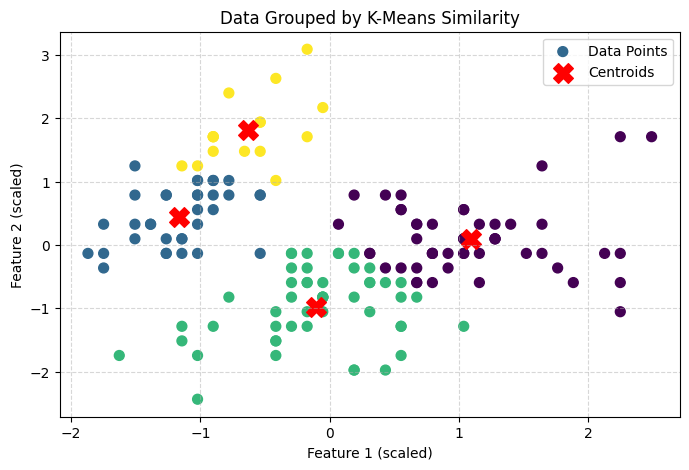

,sepal length (cm),sepal width (cm),Cluster
0,5.1,3.5,1
1,4.9,3.0,1
2,4.7,3.2,1
3,4.6,3.1,1
4,5.0,3.6,3
5,5.4,3.9,3
6,4.6,3.4,1
7,5.0,3.4,1
8,4.4,2.9,1
9,4.9,3.1,1


In [6]:
# Apply K-Means clustering
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, init='k-means++', max_iter=300, n_init=10, random_state=42)
cluster_labels = kmeans.fit_predict(X_scaled)

# Add the cluster labels back to our DataFrame
df['Cluster'] = cluster_labels

# Visualize the clustered groups and centroids
plt.figure(figsize=(8, 5))
plt.scatter(X_scaled[:, 0], X_scaled[:, 1], c=cluster_labels, s=50, cmap='viridis', label='Data Points')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=200, c='red', marker='X', label='Centroids')
plt.title('Data Grouped by K-Means Similarity')
plt.xlabel('Feature 1 (scaled)')
plt.ylabel('Feature 2 (scaled)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

display(df.head(10))